# 01 Data exploration
**All data here is synthetic** (`src/identitygraph/data/generator.py`). `fraud_label` / `fraud_scenario` are training-only.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
from identitygraph.data.ingestion import load_applications
from identitygraph.data.validation import validate
df = load_applications()
print(df.shape)
df.head(3).T

(20000, 16)


,0,1,2
application_id,APP0000001,APP0000002,APP0000003
applicant_id,APL0008587,APL0010205,APL0009827
application_timestamp,2025-01-01 00:35:25.001108423,2025-01-01 00:46:23.304304170,2025-01-01 00:51:20.285223492
full_name,Luca Baker,Morgan Baker,Omar Johnson
date_of_birth,1956-02-19,1989-03-31,1991-04-03
email,ravismith@mail.test,morgan.baker4968@mail.test,omar.johnson6037@mail.test
phone,+1-555-3588980,+1-555-7822197,+1-555-5669534
address,"4367 Hill St, Unit 89","2892 Park St, Unit 20","1555 River St, Unit 210"
device_id,dev-399826663,dev-540267792,dev-775258486
ip_address,19.195.129.49,202.223.44.35,102.222.56.226


In [2]:
v = validate(df)
{k: v[k] for k in ('ok', 'errors', 'n_rows', 'fraud_rate')}

{'ok': True, 'errors': [], 'n_rows': 20000, 'fraud_rate': 0.07}

## Fraud scenarios
Fraud is generated as clusters (rings, bursts, shared contacts) plus individual anomalies, so rates vary over time.

                         rows  fraud_rate
fraud_scenario                           
device_ring               280         1.0
identity_inconsistency    182         1.0
income_anomaly            168         1.0
legitimate              18600         0.0
shared_contact            210         1.0
synthetic_identity        350         1.0
velocity_burst            210         1.0


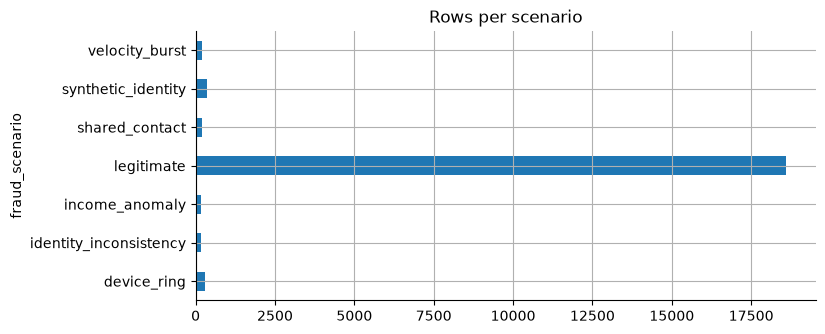

In [3]:
sc = df.groupby('fraud_scenario').agg(rows=('application_id', 'count'), fraud_rate=('fraud_label', 'mean'))
print(sc)
sc['rows'].plot.barh(title='Rows per scenario');

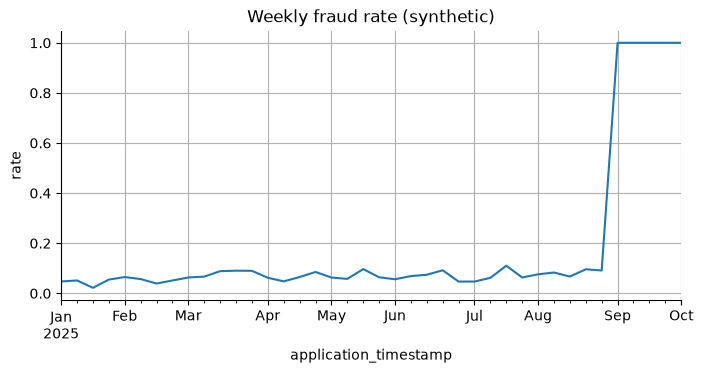

In [4]:
m = df.set_index('application_timestamp').resample('W')['fraud_label'].agg(['mean', 'size'])
ax = m['mean'].plot(title='Weekly fraud rate (synthetic)'); ax.set_ylabel('rate');

## Income vs requested credit

In [5]:
df['ratio'] = df.requested_credit / df.annual_income
df.groupby('fraud_label')['ratio'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud_label,,,,,,,,
0,18600.0,0.260463,0.187409,0.020000,0.137319,0.206823,0.319118,1.198026
1,1400.0,0.399560,0.486652,0.024294,0.143957,0.222841,0.368658,2.485880


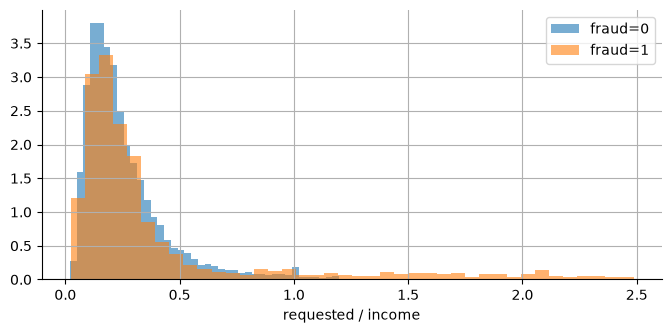

In [6]:
fig, ax = plt.subplots()
for lab, g in df.groupby('fraud_label'):
    ax.hist(g.ratio.clip(upper=2.5), bins=40, alpha=.6, density=True, label=f'fraud={lab}')
ax.set_xlabel('requested / income'); ax.legend();

In [7]:
# Entity reuse in the raw data
for c in ['device_id', 'ip_address', 'email', 'phone', 'address']:
    vc = df[c].value_counts()
    print(f'{c:12s} distinct={len(vc):6d}  max reuse={vc.iloc[0]:3d}  values used >1x={(vc > 1).sum()}')

device_id    distinct= 19449  max reuse=  8  values used >1x=244
ip_address   distinct= 19454  max reuse= 10  values used >1x=239
email        distinct= 19597  max reuse=  6  values used >1x=229
phone        distinct= 19749  max reuse=  6  values used >1x=146
address      distinct= 19122  max reuse=  8  values used >1x=427
